# 05 - Huấn luyện NN supervised (cấp 5)

**Ý tưởng**: mạng nhận thế cờ và học 2 việc cùng lúc:
- **Policy**: đoán nước mà expert chọn (64 ô; ô bất hợp lệ bị che trước khi tính loss).
- **Value**: đoán kết quả cuối ván theo góc nhìn người đang đi, trong khoảng (-1, 1).

`loss = cross-entropy(policy) + value_loss_weight * MSE(value)`.

Quy tắc bắt buộc (đề cấm vi phạm):
- Dữ liệu đã chia train/val/test **theo ván** ở notebook 04.
- Chọn checkpoint theo **val**. **Test chỉ đánh giá đúng 1 lần** ở cuối, không dùng test để chỉnh siêu tham số.
- Tăng cường dữ liệu (đối xứng bàn cờ) chỉ áp lên tập **train**.

In [1]:
import json, os, platform, sys, tempfile, time
from pathlib import Path

# Chạy từ thư mục notebooks/ hay thư mục gốc đều được: luôn chuyển về thư mục gốc repo để đường dẫn trong config đúng.
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(REPO)
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from IPython.display import display
from tqdm.auto import tqdm

from agents.nn_agent import NNAgent
from agents.registry import build_agent_by_name
from eval.tournament import play_game, random_opening
from models.nets import build_model, count_params, load_checkpoint, masked_logits, save_checkpoint
from othello.encoding import BOARD_SIZE

# QUICK_TEST = True: chạy thử cả notebook trong vài giây với dữ liệu/số vòng rất nhỏ, ghi ra thư mục tạm
# (để kiểm tra mọi thứ chạy được trước khi chạy thật). Chạy chính thức: để False.
QUICK_TEST = False

## 1. Cấu hình
Tham số lấy từ `configs/train_supervised.yaml`. Sửa trực tiếp ở ô này để thử nghiệm (ghi lại giá trị đã dùng; chọn siêu tham số chỉ dựa trên **val**).
Mỗi lần chạy chính thức đặt `RUN_NAME` **mới** (không ghi đè log cũ).

In [2]:
with open(REPO / "configs" / "train_supervised.yaml", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)
tcfg, out = cfg["train"], cfg["output"]

SEED = int(cfg["seed"])
DATA_DIR = REPO / cfg["data"]["output_dir"]
EPOCHS = int(tcfg["epochs"])
BATCH_SIZE = int(tcfg["batch_size"])
LR = float(tcfg["lr"])
WEIGHT_DECAY = float(tcfg.get("weight_decay", 0.0))
VALUE_W = float(tcfg.get("value_loss_weight", 1.0))
AUGMENT = bool(tcfg.get("augment_symmetry", False))      # 8 phép đối xứng bàn cờ, chỉ cho tập train
DEVICE = torch.device("cuda" if tcfg.get("device", "auto") == "auto" and torch.cuda.is_available()
                      else ("cpu" if tcfg.get("device", "auto") == "auto" else tcfg["device"]))
RUN_NAME = f"supervised_seed{SEED}"                      # tên thư mục log: ĐỔI cho mỗi lần chạy chính thức
CKPT_PATH = REPO / out["checkpoint_dir"] / out["checkpoint_name"]
LOG_DIR = REPO / out["log_dir"] / RUN_NAME

if QUICK_TEST:   # chạy thử nhanh trên dữ liệu mẫu 100 ván, ghi ra thư mục tạm
    tmp = Path(tempfile.mkdtemp())
    DATA_DIR, EPOCHS, CKPT_PATH, LOG_DIR = REPO / "data" / "sample", 2, tmp / "nn.pt", tmp / "log"

if LOG_DIR.exists() and any(LOG_DIR.iterdir()):
    raise FileExistsError(f"{LOG_DIR} đã có log. Đổi RUN_NAME (không ghi đè log thô).")
print(f"data={DATA_DIR}\nepochs={EPOCHS} batch={BATCH_SIZE} lr={LR} augment={AUGMENT} device={DEVICE}\ncheckpoint -> {CKPT_PATH}\nlog -> {LOG_DIR}")

data=c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\data\supervised_heuristic_v1
epochs=30 batch=256 lr=0.001 augment=True device=cpu
checkpoint -> c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\checkpoints\nn_supervised_heuristic.pt
log -> c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\logs\train_supervised_heuristic\supervised_seed42


## 2. Hàm hỗ trợ

- `to_planes`: biến (bàn cờ tuyệt đối, người đi) thành tensor (2, 8, 8): kênh 0 = quân của người đi, kênh 1 = quân đối thủ.
  Phải giống hệt `othello.encoding.encode_planes` để lúc chơi thật mạng nhìn bàn cờ giống lúc train.
- **Đối xứng**: luật Othello không đổi khi xoay/lật bàn cờ (8 phép). Ta xoay/lật thế cờ **và** nhãn nước đi tương ứng để có thêm dữ liệu miễn phí.
- `compute_losses`: policy loss dùng logit đã che nước bất hợp lệ → mạng chỉ phải "chọn trong các nước hợp lệ".
- `evaluate`: loss và accuracy trên cả một split (không augmentation). Accuracy = tỷ lệ chọn đúng nước expert.

In [3]:
N_SQUARES = BOARD_SIZE * BOARD_SIZE


def to_planes(board, player):
    """(N,8,8) int8 + (N,) -> (N,2,8,8) float32 theo góc nhìn người đi."""
    p = player.reshape(-1, 1, 1)
    return np.stack([board == p, board == -p], axis=1).astype(np.float32)


def load_split(data_dir, split):
    with np.load(Path(data_dir) / f"{split}.npz") as z:
        return {k: z[k] for k in z.files}


def _symmetry_tables():
    idx = np.arange(N_SQUARES).reshape(BOARD_SIZE, BOARD_SIZE)
    perms = []
    for flip in (False, True):
        for rot in range(4):
            t = np.rot90(idx, rot)
            t = np.fliplr(t) if flip else t
            perms.append(t.ravel().copy())
    perms = np.stack(perms)                  # perms[k][i] = ô CŨ chuyển tới ô mới i
    return perms, np.argsort(perms, axis=1)  # inv[k][a]   = ô MỚI của ô cũ a

SYM_PERMS_NP, SYM_INV_NP = _symmetry_tables()
SYM_PERMS, SYM_INV = torch.from_numpy(SYM_PERMS_NP).long(), torch.from_numpy(SYM_INV_NP).long()


def apply_symmetry(planes, legal, action, k):
    """Áp phép đối xứng k[b] (0..7) cho từng mẫu. Nhãn value không đổi (kết quả ván không đổi khi xoay bàn)."""
    b = planes.shape[0]
    perm = SYM_PERMS.to(planes.device)[k]
    flat = planes.reshape(b, 2, N_SQUARES)
    new_planes = flat.gather(2, perm.unsqueeze(1).expand(b, 2, N_SQUARES)).reshape(b, 2, BOARD_SIZE, BOARD_SIZE)
    return new_planes, legal.gather(1, perm), SYM_INV.to(planes.device)[k, action]


def to_tensors(split, device):
    return {"planes": torch.from_numpy(to_planes(split["board"], split["player"])).to(device),
            "legal": torch.from_numpy(split["legal"]).to(device),
            "action": torch.from_numpy(split["action"].astype(np.int64)).to(device),
            "value": torch.from_numpy(split["value"]).to(device)}


def compute_losses(model, planes, legal, action, value, value_w):
    logits, v_pred = model(planes)
    masked = masked_logits(logits, legal)                    # ô bất hợp lệ -> -1e9
    policy_loss = F.cross_entropy(masked, action)
    value_loss = F.mse_loss(v_pred, value)
    acc = (masked.argmax(1) == action).float().mean()
    return policy_loss + value_w * value_loss, policy_loss, value_loss, acc


@torch.no_grad()
def evaluate(model, data, value_w, batch_size=4096):
    model.eval()
    n = len(data["action"])
    tot = {"loss": 0.0, "policy_loss": 0.0, "value_loss": 0.0, "acc": 0.0}
    for i in range(0, n, batch_size):
        sl = slice(i, i + batch_size)
        loss, pl, vl, acc = compute_losses(model, data["planes"][sl], data["legal"][sl], data["action"][sl],
                                           data["value"][sl], value_w)
        m = len(data["action"][sl])
        for k, v in zip(tot, (loss, pl, vl, acc)):
            tot[k] += v.item() * m
    return {k: v / n for k, v in tot.items()}


def baselines(split):
    """Mức tham chiếu để biết mạng học được gì hơn đoán mò (đưa vào báo cáo)."""
    return {"random_legal_move_accuracy": float(np.mean(1.0 / split["legal"].sum(1))),
            "value_mse_predict_zero": float(np.mean(split["value"] ** 2)),
            "value_mse_predict_mean": float(np.var(split["value"]))}


def show_progress(history, best_epoch=None):
    """Vẽ lại đường cong sau mỗi epoch (xóa hình cũ) để theo dõi lúc train."""
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
    ax[0].set_title("Tổng loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h.epoch, h.train_acc, label="train"); ax[1].plot(h.epoch, h.val_acc, label="val")
    ax[1].set_title("Accuracy (trùng nước expert)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    if best_epoch:
        for a in ax: a.axvline(best_epoch, color="gray", ls="--", lw=1)
    plt.tight_layout(); plt.show()

## 3. Nạp dữ liệu và kiểm tra
Kiểm tra lại không có ván nào nằm ở 2 split. Planes được mã hóa **một lần** cho cả split để mỗi epoch nhanh hơn.

In [4]:
torch.manual_seed(SEED); np.random.seed(SEED)
gen = torch.Generator().manual_seed(SEED)                # xáo trộn lô + chọn phép đối xứng, tái lập theo seed

raw = {s: load_split(DATA_DIR, s) for s in ("train", "val", "test")}
gids = {s: set(np.unique(raw[s]["game_id"]).tolist()) for s in raw}
assert not (gids["train"] & gids["val"] or gids["train"] & gids["test"] or gids["val"] & gids["test"]), "Rò rỉ giữa split!"
data = {s: to_tensors(raw[s], DEVICE) for s in raw}
data_meta = json.load(open(DATA_DIR / "meta.json", encoding="utf-8"))
display(pd.DataFrame({"số ván": data_meta["games_per_split"], "số mẫu": data_meta["samples_per_split"]}))
print("Nguồn nhãn:", data_meta["label_source"]["expert_agent"],
      "(TẠM THỜI)" if data_meta["label_source"].get("is_temporary_expert") else "")
print("planes", tuple(data["train"]["planes"].shape), "| legal", tuple(data["train"]["legal"].shape))

,số ván,số mẫu
train,4000,239311
val,500,29987
test,500,29946


Nguồn nhãn: heuristic 
planes (239311, 2, 8, 8) | legal (239311, 64)


## 4. Mạng và optimizer
Kiến trúc nằm ở `models/nets.py` (3 lớp conv 3x3 + đầu policy + đầu value).

In [5]:
model = build_model(cfg["model"]).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
print(model)
print(f"Số tham số: {count_params(model):,}")

PolicyValueNet(
  (conv1): Conv2d(2, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (policy_conv): Conv2d(64, 4, kernel_size=(1, 1), stride=(1, 1))
  (policy_fc): Linear(in_features=256, out_features=64, bias=True)
  (value_conv): Conv2d(64, 8, kernel_size=(1, 1), stride=(1, 1))
  (value_fc1): Linear(in_features=512, out_features=128, bias=True)
  (value_fc2): Linear(in_features=128, out_features=1, bias=True)
)
Số tham số: 158,093


## 5. Vòng huấn luyện
Mỗi epoch: (1) xáo trộn tập train, (2) với từng lô: áp đối xứng ngẫu nhiên (nếu bật) → forward → loss → backward → cập nhật,
(3) đo loss/accuracy trên **val**, (4) nếu val loss tốt nhất từ trước tới giờ thì lưu checkpoint.

Hình tự cập nhật sau mỗi epoch. Dấu hiệu cần để ý:
- train loss giảm nhưng val loss tăng → overfit (giảm epoch, thêm augmentation/weight decay, thêm dữ liệu).
- accuracy rất cao + dữ liệu từ expert đơn giản → mạng chỉ học lại expert (rủi ro đề mục 3.4), chưa chắc chơi mạnh.

  0%|          | 0/30 [00:00<?, ?it/s]

epoch 1/30 | train loss 2.1222 acc 0.466 | val loss 1.8585 acc 0.550 | best epoch 1 | 49.46s
epoch 2/30 | train loss 1.8350 acc 0.570 | val loss 1.7447 acc 0.587 | best epoch 2 | 45.34s
epoch 3/30 | train loss 1.7540 acc 0.599 | val loss 1.6878 acc 0.606 | best epoch 3 | 44.74s
epoch 4/30 | train loss 1.7023 acc 0.616 | val loss 1.6447 acc 0.623 | best epoch 4 | 44.8s
epoch 5/30 | train loss 1.6649 acc 0.630 | val loss 1.6245 acc 0.632 | best epoch 5 | 44.62s
epoch 6/30 | train loss 1.6399 acc 0.638 | val loss 1.5986 acc 0.639 | best epoch 6 | 96.83s
epoch 7/30 | train loss 1.6175 acc 0.646 | val loss 1.5862 acc 0.646 | best epoch 7 | 61.57s
epoch 8/30 | train loss 1.6009 acc 0.652 | val loss 1.5680 acc 0.650 | best epoch 8 | 43.66s
epoch 9/30 | train loss 1.5867 acc 0.656 | val loss 1.5571 acc 0.652 | best epoch 9 | 44.04s
epoch 10/30 | train loss 1.5749 acc 0.660 | val loss 1.5513 acc 0.655 | best epoch 10 | 44.26s
epoch 11/30 | train loss 1.5639 acc 0.664 | val loss 1.5417 acc 0.659

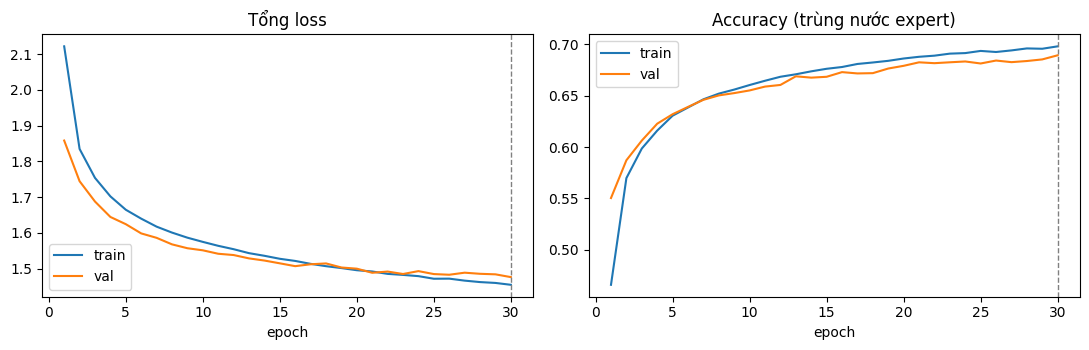

In [6]:
history, best = [], {"val_loss": float("inf"), "epoch": 0}
n_train = len(data["train"]["action"])
t_start = time.perf_counter()
for epoch in tqdm(range(1, EPOCHS + 1)):
    t0 = time.perf_counter()
    model.train()
    order = torch.randperm(n_train, generator=gen).to(DEVICE)
    tot = {"loss": 0.0, "policy_loss": 0.0, "value_loss": 0.0, "acc": 0.0}
    for i in range(0, n_train, BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        planes, legal = data["train"]["planes"][idx], data["train"]["legal"][idx]
        action, value = data["train"]["action"][idx], data["train"]["value"][idx]
        if AUGMENT:                                                   # mỗi mẫu một phép đối xứng ngẫu nhiên
            k = torch.randint(0, 8, (len(idx),), generator=gen).to(DEVICE)
            planes, legal, action = apply_symmetry(planes, legal, action, k)
        loss, pl, vl, acc = compute_losses(model, planes, legal, action, value, VALUE_W)
        opt.zero_grad(); loss.backward(); opt.step()
        for key, v in zip(tot, (loss, pl, vl, acc)):
            tot[key] += v.item() * len(idx)
    tr = {k: v / n_train for k, v in tot.items()}
    va = evaluate(model, data["val"], VALUE_W)
    history.append({"epoch": epoch,
                    "train_loss": tr["loss"], "train_policy_loss": tr["policy_loss"],
                    "train_value_loss": tr["value_loss"], "train_acc": tr["acc"],
                    "val_loss": va["loss"], "val_policy_loss": va["policy_loss"],
                    "val_value_loss": va["value_loss"], "val_acc": va["acc"],
                    "seconds": round(time.perf_counter() - t0, 2)})
    if va["loss"] < best["val_loss"]:                                 # chọn checkpoint theo VAL, không nhìn test
        best = {"val_loss": va["loss"], "val_acc": va["acc"], "epoch": epoch}
        save_checkpoint(CKPT_PATH, model, meta={
            "kind": "supervised", "seed": SEED, "epoch": epoch, "val_loss": va["loss"], "val_acc": va["acc"],
            "train_config": cfg, "label_source": data_meta["label_source"]})
    print(f"epoch {epoch}/{EPOCHS} | train loss {tr['loss']:.4f} acc {tr['acc']:.3f} | "
          f"val loss {va['loss']:.4f} acc {va['acc']:.3f} | best epoch {best['epoch']} | {history[-1]['seconds']}s")
show_progress(history, best["epoch"])
train_seconds = time.perf_counter() - t_start

## 6. Đánh giá test (đúng 1 lần) và lưu log
Nạp lại checkpoint **tốt nhất theo val** rồi mới đo test. Sau bước này không được quay lại chỉnh siêu tham số dựa trên số test.

In [7]:
best_model, _ = load_checkpoint(CKPT_PATH, device=DEVICE)
test = evaluate(best_model, data["test"], VALUE_W)
base = baselines(raw["test"])
display(pd.DataFrame({
    "chỉ số": ["test accuracy (trùng nước expert)", "đoán ngẫu nhiên trong nước hợp lệ", "test value MSE",
               "value MSE nếu luôn đoán 0", "value MSE nếu luôn đoán trung bình"],
    "giá trị": [test["acc"], base["random_legal_move_accuracy"], test["value_loss"],
                base["value_mse_predict_zero"], base["value_mse_predict_mean"]]}))

LOG_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame(history).to_csv(LOG_DIR / "epochs.csv", index=False)       # notebook 03 đọc file này
with open(LOG_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump({"best_epoch": best["epoch"], "test": test, "baselines": base,
               "note": "test_acc = tỷ lệ trùng nước với expert (đo nguy cơ 'học lại expert', đề mục 3.4)."},
              f, ensure_ascii=False, indent=2)
with open(LOG_DIR / "meta.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "device": str(DEVICE),
               "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
               "cpu": platform.processor() or platform.machine(), "torch": torch.__version__,
               "train_seconds": round(train_seconds, 1), "n_params": count_params(model),
               "samples": data_meta["samples_per_split"], "label_source": data_meta["label_source"],
               "best_epoch": best["epoch"], "config": cfg}, f, ensure_ascii=False, indent=2)
print(f"Đã lưu log vào {LOG_DIR}\nCheckpoint tốt nhất (epoch {best['epoch']}): {CKPT_PATH}\nThời gian train: {train_seconds:.0f}s trên {DEVICE}")

,chỉ số,giá trị
0,test accuracy (trùng nước expert),0.694216
1,đoán ngẫu nhiên trong nước hợp lệ,0.189439
2,test value MSE,0.737378
3,value MSE nếu luôn đoán 0,0.969946
4,value MSE nếu luôn đoán trung bình,0.969908


Đã lưu log vào c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\results\logs\train_supervised_heuristic\supervised_seed42
Checkpoint tốt nhất (epoch 30): c:\Users\ACER\Documents\CODING\TTNTNC\Advanced_Artificial_Intelligience_Group\Project_final\checkpoints\nn_supervised_heuristic.pt
Thời gian train: 1422s trên cpu


## 7. Kiểm tra nhanh bằng cách chơi thật (sanity check, KHÔNG phải kết quả chính thức)
Cho NNAgent đấu `random` 20 ván (chia đều Đen/Trắng, cùng khai cuộc theo cặp) để chắc chắn checkpoint chơi được và hợp lệ.
Đánh giá chính thức nằm ở giải đấu (`eval/tournament.py`) với seed riêng.

In [8]:
agent_nn = NNAgent(checkpoint=str(CKPT_PATH), name="NN")
w = d = l = 0
for pair in range(10):
    opening = random_opening(777_000 + pair, 4)                          # seed riêng cho sanity check
    for nn_black in (True, False):
        rnd = build_agent_by_name("random", seed=pair)
        black, white = (agent_nn, rnd) if nn_black else (rnd, agent_nn)
        rec = play_game(black, white, None, None, opening)
        outcome = rec["result_black"] * (1 if nn_black else -1)
        w, d, l = w + (outcome == 1), d + (outcome == 0), l + (outcome == -1)
print(f"NN vs Random (20 ván): thắng {w} / hòa {d} / thua {l}  (chỉ để kiểm tra checkpoint chạy đúng)")

NN vs Random (20 ván): thắng 19 / hòa 1 / thua 0  (chỉ để kiểm tra checkpoint chạy đúng)
